In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
import os
# root_folder="/home/tristan/code/SINETRA/"
# data='hydra_flow/0.2-50.0'
# model_path="/mnt/helix/FeatureNet_seg/training_logs/SiameseUNet/32feat_True_pos/0.2-50.0/version_0/checkpoints/best_model_epoch=89.ckpt"
# subfolders=[None,None,"333"]
# video_path="/home/tristan/code/SINETRA/dataset/hydra_flow/0.2-50.0/333/video.tiff"
# n_frames=100


root_folder="/home/tristan/code/SINETRA/dataset/hydra_flow"
data="0.2-50.0"
model_path="/mnt/helix/FeatureNet_tra/training_logs/tracking/SiameseUNet_aug/0.2-50.0/version_2/checkpoints/best_model_epoch=87.ckpt"
subfolders=[None,None,"333"]
video_path="/home/tristan/code/SINETRA/dataset/hydra_flow/0.2-50.0/333/video.tiff"
n_frames=5
min_cell_size=1000

In [2]:
from models.unet import SiameseUNet
from lightning import Trainer
from lightning.pytorch.loggers import TensorBoardLogger
from data.data import SpagDataModule
from lightning.pytorch.callbacks import ModelCheckpoint

data_module=SpagDataModule(
    root_folder=os.path.join(root_folder,data),
    subfolders=subfolders,
    batch_size=1,
    max_length_of_training_samples=2,
    max_length_of_validation_samples=2,
    max_length_of_testing_samples=n_frames,
    expected_min=0,
    expected_max=255
)

Found min and max values of images:  0 255
Normalizing images to [0, 1] using expected_min and expected_max:  0 255
######## Successfully loaded datasets ########
Root folder: /home/tristan/code/SINETRA/dataset/hydra_flow/0.2-50.0
Train dataset length: N/A
Val dataset length: N/A
Test dataset length: 5
###############################################


In [2]:
import torch

# 1. Instantiate the model with the exact same arguments used during training
model = SiameseUNet(
    # in_channels=3,  (Add your initialization arguments here if you have any)
    # feature_dim=64
)

checkpoint_path = model_path  # Path to your checkpoint file

# 2. Load the raw checkpoint file
checkpoint = torch.load(checkpoint_path, map_location="cpu")

# 3. Handle different save formats
if "state_dict" in checkpoint:
    # Sometimes raw saves still wrap the weights in a 'state_dict' key
    model.load_state_dict(checkpoint["state_dict"])
    print("Loaded model from checkpoint with 'state_dict' key.")
else:
    # Otherwise, the checkpoint is likely just the weights dictionary itself
    model.load_state_dict(checkpoint)

model.eval()

NameError: name 'SiameseUNet' is not defined

In [ ]:
# model= SiameseUNet.load_from_checkpoint(
#     checkpoint_path=model_path)
#     # checkpoint_path='./training_logs/SiameseUNet_aug/Fluo-N2DH-GOWT1/version_0/checkpoints/best_model.ckpt')
# model.eval()

SiameseUNet(
  (loss_fn_seg): BCEWithLogitsLoss()
  (model): SiameseUNetBase(
    (down): UnetDown(
      (encoder): ModuleList(
        (0): UNetBlock(
          (block): Sequential(
            (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (3): ReLU(inplace=True)
          )
        )
        (1): UNetBlock(
          (block): Sequential(
            (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (3): ReLU(inplace=True)
          )
        )
        (2): UNetBlock(
          (block): Sequential(
            (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): ReLU(inplace=True)
            (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1

In [5]:
preds, per_instance_features, per_instance_variance = model.predict(data_module, dataloader='test', disable_tqdm=False, cluster_method='' \
'dbscan', min_cell_size=min_cell_size,connected_components=False)

#save the predictions, features, and variance to a file
import pickle
import os 
if not os.path.exists(os.path.join("results", data)):
    os.makedirs(os.path.join('./results', data))
with open(os.path.join('./results', data, 'preds.pkl'), 'wb') as f:
    pickle.dump(preds, f)
with open(os.path.join('./results', data, 'per_instance_features.pkl'), 'wb') as f:
    pickle.dump(per_instance_features, f)
with open(os.path.join('./results', data, 'per_instance_variance.pkl'), 'wb') as f:
    pickle.dump(per_instance_variance, f)

Predicting:   0%|          | 0/50 [00:00<?, ?it/s]

Clustering 76348 foreground pixels using DBSCAN...


Predicting:   2%|▏         | 1/50 [00:02<01:46,  2.17s/it]

Detected 22 instances.
Clustering 75717 foreground pixels using DBSCAN...


Predicting:   4%|▍         | 2/50 [00:03<01:25,  1.79s/it]

Detected 22 instances.
Clustering 75030 foreground pixels using DBSCAN...


... (92 outputs left out)

Predicting:  98%|█████████▊| 49/50 [01:21<00:01,  1.74s/it]

Detected 26 instances.
Clustering 87420 foreground pixels using DBSCAN...


Predicting: 100%|██████████| 50/50 [01:22<00:00,  1.66s/it]

Detected 26 instances.


In [6]:
per_instance_variance[0][1]

tensor(1.)

Instance 1 variance norm: 1000000.0
Instance 2 variance norm: 134312.046875
Instance 3 variance norm: 146286.0
Instance 4 variance norm: 4259.2978515625
Instance 5 variance norm: 0.0
Instance 6 variance norm: 5540.337890625
Instance 7 variance norm: 58423.54296875
Instance 8 variance norm: 206416.15625
Instance 9 variance norm: 6374.19287109375
Instance 10 variance norm: 49037.09765625
Instance 11 variance norm: 85793.3046875
Instance 12 variance norm: 43755.5625
Instance 13 variance norm: 9399.033203125
Instance 14 variance norm: 79571.7734375
Instance 15 variance norm: 51112.58984375
Instance 16 variance norm: 37022.34375
Instance 17 variance norm: 28979.892578125
Instance 18 variance norm: 18343.53125
Instance 19 variance norm: 18467.28515625
Instance 20 variance norm: 64565.62890625
Instance 21 variance norm: 4458.2275390625
Instance 22 variance norm: 21924.662109375
Instance 1 variance norm: 1000000.0
Instance 2 variance norm: 128604.265625
Instance 3 variance norm: 105759.21875
I

Text(0.5, 1.0, 'Predicted Variance')

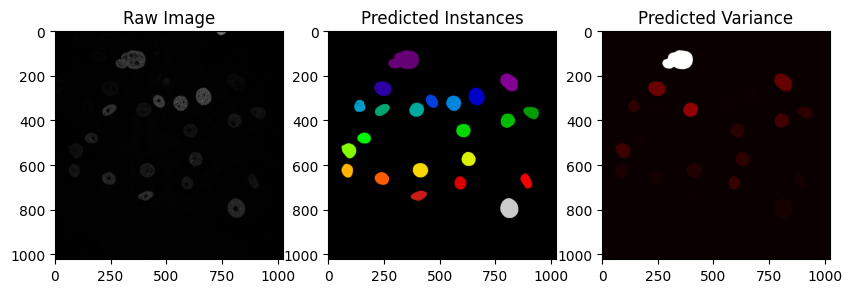

In [7]:
import numpy as np
import tifffile
var_masks=[]
for i in range(len(preds)):
    var_mask = np.zeros_like(preds[i])
    for j in np.unique(preds[i]):
        if j==0:
            continue
        norm = per_instance_variance[i][j]*1e6
        print(f"Instance {j} variance norm: {norm}")
        var_mask[preds[i]==j] = norm
    var_masks.append(var_mask)

import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
plt.subplot(1,3,1)
plt.imshow(tifffile.imread(video_path)[0], cmap='gray')
plt.title("Raw Image")
plt.subplot(1,3,2)
plt.imshow(np.array(preds[0]), cmap='nipy_spectral')
plt.title("Predicted Instances")
plt.subplot(1,3,3)
plt.imshow(np.array(var_masks[0]), cmap='hot')
plt.title("Predicted Variance")

In [8]:
import napari
import tifffile
import numpy as np
# gt=[data_module.test_ds[i][1].detach().cpu().numpy().squeeze() for i in range(len(data_module.test_ds))]
viewer=napari.Viewer()
viewer.add_image(tifffile.imread(video_path), name="raw")
# viewer.add_labels(np.array(gt).astype(np.uint8), name="GT")
viewer.add_labels(np.array(preds).astype(np.uint8), name="Predicted Instances")
viewer.add_image(np.array(var_masks), name="Predicted Variance")

<Image layer 'Predicted Variance' at 0x7702303b3580>

# FIRST TRY NAIVE DBSCAN

In [9]:
# #tsne on per_instance_features

# import matplotlib.pyplot as plt
# from sklearn.manifold import TSNE

# #per instance feature in a list of dicts where key is label and value is feature vector

# list_of_features = []
# frame_ids = []
# cell_ids = []
# for i in range(len(per_instance_features)):
#     for label, feature in per_instance_features[i].items():
#         list_of_features.append(feature)
#         frame_ids.append(i)
#         cell_ids.append(label)
# list_of_features = np.array(list_of_features)


# tsne = TSNE(n_components=2, random_state=42)
# tsne_results = tsne.fit_transform(list_of_features)


# fig=plt.figure(figsize=(10, 10))
# plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=frame_ids, cmap='viridis', alpha=0.7, s=200,  marker="x")
# plt.colorbar(label='Frame ID')
# plt.title('t-SNE of Per-Instance Features')



In [10]:
# from sklearn.cluster import HDBSCAN, KMeans,DBSCAN

# def cluster_features(features, method='hdbscan', eps=0.5, min_samples=5, n_clusters=None):
#     if method == 'hdbscan':
#         clustering_model = HDBSCAN(min_cluster_size=5)
#     elif method == 'kmeans':
#         if n_clusters is None:
#             raise ValueError("n_clusters must be specified for kmeans.")
#         clustering_model = KMeans(n_clusters=n_clusters, random_state=42)
#     else:
#         raise ValueError("Unsupported clustering method. Choose 'hdbscan' or 'kmeans'.")
    
#     labels = clustering_model.fit_predict(features)
#     labels=labels+1
#     return labels


# print([len(per_instance_features[i]) for i in range(len(per_instance_features))])
# avg_n_cells=np.mean([len(per_instance_features[i]) for i in range(len(per_instance_features))])
# print(f"Average number of cells per frame: {avg_n_cells}")

# labels_tracks = cluster_features(list_of_features, method='hdbscan', eps=0.5, min_samples=2, n_clusters=int(avg_n_cells))
# # kmeans = KMeans(n_clusters=int(avg_n_cells)+1, random_state=42)
# # kmeans_labels = kmeans.fit_predict(tsne_results)
# # print(kmeans_labels)
# print(np.unique(labels_tracks))


In [11]:
# #import regionprops to get the centroid of each instance mask
# from skimage.measure import regionprops
# #rebuild labels based on kmeans clustering

# tracks=[]
# for i, frame in enumerate(frame_ids):
#     target=[]
#     target.append(labels_tracks[i])
#     target.append(frame)
#     mask=preds[frame]==cell_ids[i]
#     mask=mask.astype(np.uint8)
#     props=regionprops(mask)
#     target.append(props[0].centroid[0])
#     target.append(props[0].centroid[1])
#     tracks.append(target)

# import napari
# viewer=napari.Viewer()
# viewer.add_image(tifffile.imread("/home/tristan/data/CTC_SINETRA_seg/Fluo-N2DH-GOWT1/02/video.tiff"), name="raw")
# viewer.add_labels(np.array(gt).astype(np.uint8), name="GT") 
# viewer.add_labels(np.array(preds).astype(np.uint8), name="Predicted Instances")
# viewer.add_tracks(np.array(tracks), name="Predicted Tracks")


# VISUALMHT

In [1]:
model=None
import pickle
#reload the predictions, features, and variance from the file
with open(os.path.join('./results', data, 'preds.pkl'), 'rb') as f:
    preds = pickle.load(f)
with open(os.path.join('./results', data, 'per_instance_features.pkl'), 'rb') as f:
    per_instance_features = pickle.load(f)
with open(os.path.join('./results', data, 'per_instance_variance.pkl'), 'rb') as f:
    per_instance_variance = pickle.load(f)  
    

NameError: name 'os' is not defined

In [13]:
from utils_tracking import reformat_model_output_as_byotrack_detections, reformat_model_output_as_byotrack_detections_single_thread
detections = reformat_model_output_as_byotrack_detections_single_thread(preds, per_instance_features, per_instance_variance)

100%|██████████| 50/50 [00:00<00:00, 216.85it/s]


In [14]:
from visual_mht.src.linkers.visual_mht import VisualMHTLinker, VisualMHTLinkerParameters
from byotrack import FeaturesExtractor
import torch
specs=VisualMHTLinkerParameters(
        association_threshold= -1.0,
        detection_std = 1.0,
        process_std = 2.0,
        kalman_order= 1,
        fpr= 0.1,
        fnr = 0.1,
        birth_rate = 1e-4,
        death_rate = 1e-4,
        tree_depth = 3,
        step = 1,
        n_det = -1.0,
        volume = -1.0,
        n_0 = -1.0,
        std =2.5,
        model_cutoff = 10.0,
        features_cutoff = 3.0,
        features_ema = 0.5,
        features_std = 0.4,
        drop_trailing = False,
        false_tracks = True,
        initial_std_factor = 3.0,
        solver="scipy",
        track_building="smoothed"
)
linker=VisualMHTLinker(specs, features_extractor=FeaturesExtractor)

linker.debug = False
linker.device = torch.device("cpu")

/home/tristan/code/FeatureNet_seg/visual_mht/src/linkers/bskt.py:311: UserWarning: The model_cutoff (10.0) given will be ignored for non MODEL Costs (Cost.EUCLIDEAN).
  warnings.warn(f"The model_cutoff ({model_cutoff}) given will be ignored for non MODEL Costs ({cost}).")


In [15]:
import byotrack
video = byotrack.Video(video_path)[:n_frames]

tracks=linker.run(video,detections)

Visual MHT linking:   0%|          | 0/50 [00:00<?, ?it/s]

/home/tristan/code/FeatureNet_seg/visual_mht/src/linkers/base.py:1383: UserWarning: Some features are already computed. They will be used.
  warnings.warn("Some features are already computed. They will be used.")


In [16]:
from utils_tracking import _tracks_to_napari
import napari
import numpy as np
import tifffile
viewer=napari.Viewer()
viewer.add_image(tifffile.imread(video_path)[:n_frames], name="raw")
# viewer.add_labels(np.array(gt).astype(np.uint8), name="GT")
viewer.add_labels(np.array(preds).astype(np.uint8), name="Predicted Instances")
viewer.add_tracks(_tracks_to_napari(tracks), name="Predicted Tracks")

<Tracks layer 'Predicted Tracks' at 0x770228b07f10>

In [17]:
from visual_mht.tracking_eval import compute_tracking_metrics
import torch

ground_truth=torch.load("/home/tristan/code/SINETRA/dataset/hydra_flow/0.2-50.0/333/video_data.pt")
results= compute_tracking_metrics(tracks, ground_truth)
print(results["HOTA"][-8])

tensor(0.0060)
